![uwm_logo1_pl.svg](https://uwm.edu.pl/sites/default/files/2023-01/uwm_logo_poziome_PL.png)

# Symulacje komputerowe
## Laboratorium 02 - Chaos deterministyczny
**mgr inż. Adam Zalewski**<br>
na podstawie materiałów **dra hab. inż. Mariusza Bodziocha, prof. UWM**

**Zadanie 0.** Zaimportuj niezbędne biblioteki.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp

### Układ Chua

Układ Chua - opisuje zachowanie deterministyczne obwodu elektronicznego wykazującego chaos. Jest to jeden z najważniejszych modeli w teorii chaosu, ponieważ był pierwszym układem fizycznym (zbudowanym z rzeczywistych komponentów w 1983 roku przez Leona Chua), w którym udało się eksperymentalnie dowieść i zaobserwować zjawisko chaosu deterministycznego.

W sensie fizycznym układ równań opisuje przepływ prądu i zmiany napięć w nieskomplikowanym obwodzie nieliniowym. Obwód ten składa się z pięciu podstawowych elementów:
- Dwóch kondensatorów (gromadzących ładunek i napięcie).
- Jednej cewki indukcyjnej (gromadzącej energię pola magnetycznego i prąd).
- Jednego liniowego rezystora.
- Diody Chua (tzw. nieliniowego rezystora): Jest to kluczowy, aktywny element obwodu, który ma specyficzną, nieliniową charakterystykę prądowo-napięciową (ujemną rezystancję w pewnym pasmie). To ona "pcha" układ w stronę zachowań chaotycznych.

Układ Chua dany jest następującymi równaniami różniczkowymi:

$$ \begin{array}{l}
    \frac{dx}{dt} = \alpha\left(y-x-f(x)\right)\\
    \frac{dy}{dt} = x - y + z\\
    \frac{dz}{dt} = -\beta y
    \end{array} $$

Gdzie $f(x)$ to funkcja nieliniowa postaci:

$$f(x)=m_1 x+(m_0 - m_1)\frac{|x+1|-|x-1|}{2}$$

Matematycznie układ opisuje dynamikę trzech powiązanych ze sobą zmiennych stanu w czasie (\(t\)):
- $x$ – reprezentuje napięcie na pierwszym kondensatorze ($V_{1}$).
- $y$ – reprezentuje napięcie na drugim kondensatorze ($V_{2}$).
- $z$ – reprezentuje prąd płynący przez cewkę indukcyjną ($I_{L}$).
  
Układ trzech równań różniczkowych precyzyjnie definiuje, jak zmiana jednej z tych wartości (np. prądu) natychmiast wpływa na pozostałe dwie (napięcia).

**Zadanie 1.** **Zadanie 1.** Zaimplementuj funkcję pomocniczą $f(x)$ jako <code>def function(x, m0, m1)</code> oraz funkcję <code>def chua(t, state, alpha, beta, m0, m1)</code> dla domyślnych wartości $\alpha=15.6$, $\beta=28$, $m_0=-1.143$ oraz $m_1=-0.714$, która zwraca tablicę obliczonych pochodnych $\frac{dx}{dt}$, $\frac{dy}{dt}$ oraz $\frac{dz}{dt}$.

In [4]:
from jedi.settings import dynamic_params


def function(x, m0=-1.143, m1=-0.714):
    return m1 * x + (m0 - m1) * (abs(x+1)-abs(x-1))/2

def chua(t, state, alpha=15.6, beta=28, m0=-1.143, m1=-0.714):
    x, y, z = state
    dx = alpha * (y - x - function(x, m0, m1))
    dy = x - y + z
    dz = - beta * y
    return [dx, dy, dz]


**Zadanie 2.** Dla $t=0,...,50$ i punkcie początkowym o współrzędnych $(0.7,0,-0.7)$ wyświetl wykres dla $x$, $y$ oraz $z$ układu Chua. Wykorzystaj <code>from scipy.integrate import solve_ivp</code>

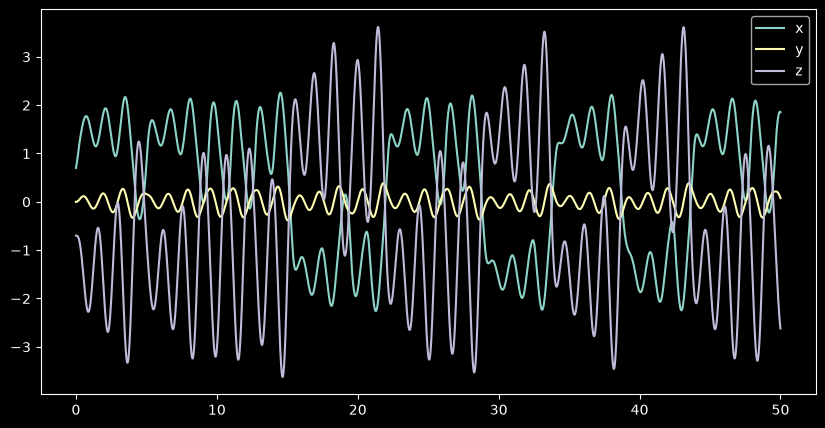

In [5]:
t_span = (0, 50)
t_eval = np.linspace(*t_span, 10000)

sol_1 = solve_ivp(chua, t_span, [0.7, 0, -0.7], t_eval=t_eval)

plt.figure(figsize=(10, 5))
plt.plot(sol_1.t, sol_1.y[0], label="x")
plt.plot(sol_1.t, sol_1.y[1], label="y")
plt.plot(sol_1.t, sol_1.y[2], label="z")

plt.legend()
plt.show()

**Zadanie 3.** Dla $t=0,...,50$ i punkcie początkowym o współrzędnych $(0.701, 0, -0.701)$ wyświetl wykres dla $x$, $y$ oraz $z$ układu Chua. Wykorzystaj <code>from scipy.integrate import solve_ivp</code>

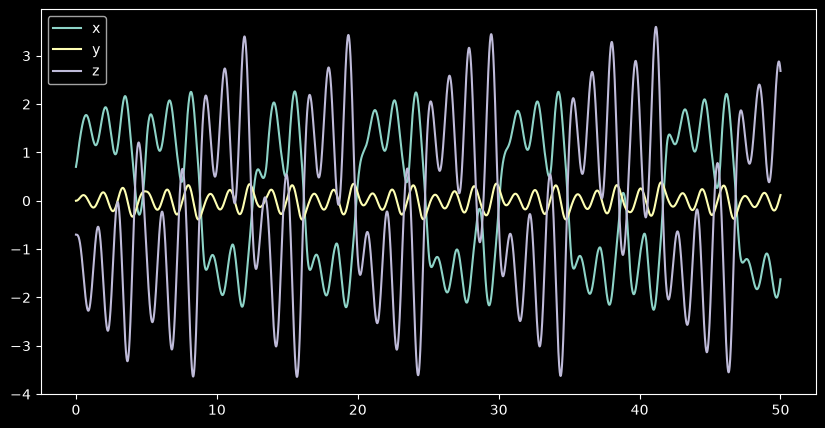

In [6]:
t_span = (0, 50)
t_eval = np.linspace(*t_span, 10000)

sol_2 = solve_ivp(chua, t_span, [0.701, 0, -0.701], t_eval=t_eval)

plt.figure(figsize=(10, 5))
plt.plot(sol_2.t, sol_2.y[0], label="x")
plt.plot(sol_2.t, sol_2.y[1], label="y")
plt.plot(sol_2.t, sol_2.y[2], label="z")

plt.legend()
plt.show()

**Zadanie 4.** Dla rozwiązań z zadań 2 i 3 wyświetl:

**4.1** wykres $x$ względem $t$

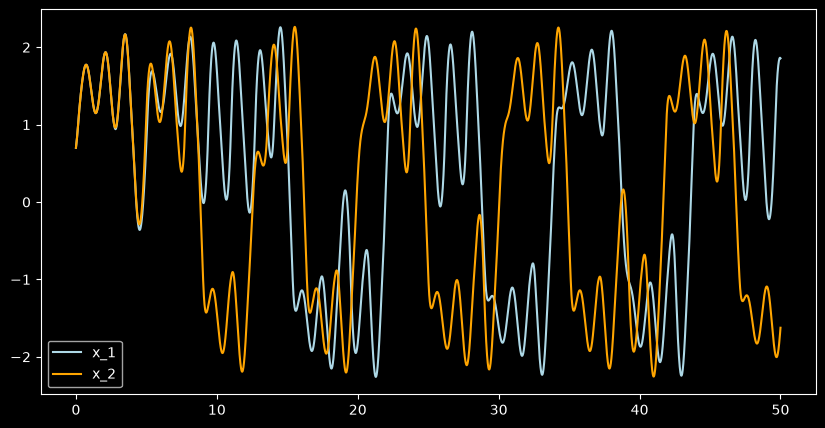

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(sol_1.t, sol_1.y[0], label="x_1", color="lightblue")
plt.plot(sol_2.t, sol_2.y[0], label="x_2", color="orange")

plt.legend()
plt.show()

**4.2** wykres $y$ względem $t$

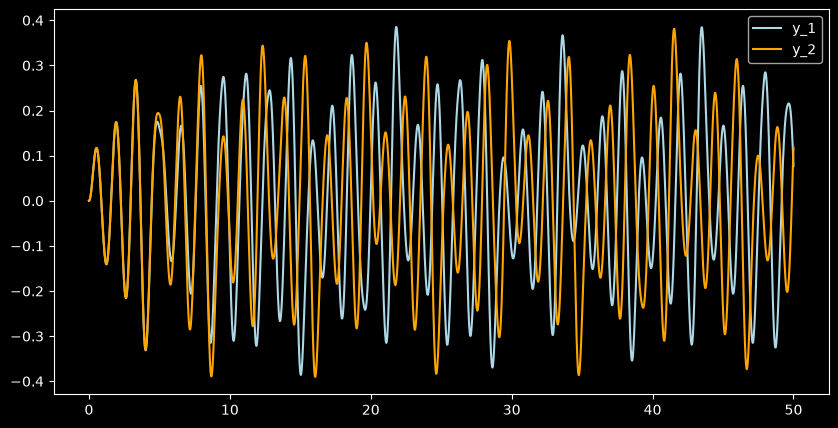

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(sol_1.t, sol_1.y[1], label="y_1", color="lightblue")
plt.plot(sol_2.t, sol_2.y[1], label="y_2", color="orange")

plt.legend()
plt.show()

**4.3** wykres $z$ względem $t$

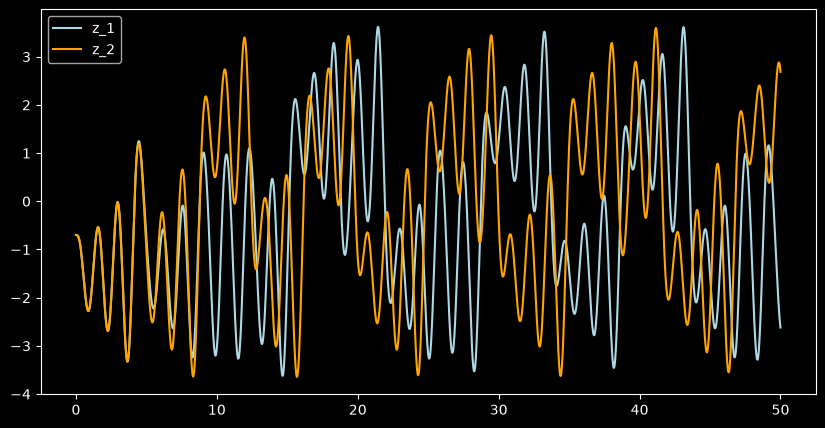

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(sol_1.t, sol_1.y[2], label="z_1", color="lightblue")
plt.plot(sol_2.t, sol_2.y[2], label="z_2", color="orange")

plt.legend()
plt.show()

**Zadanie 5.** Na płaszczyźnie dwuwymiarowej wygeneruj wykres atraktora układu Chua dla rozwiązań z zadań 2 i 3.

**5.1** Wykres dla $(x,y)$

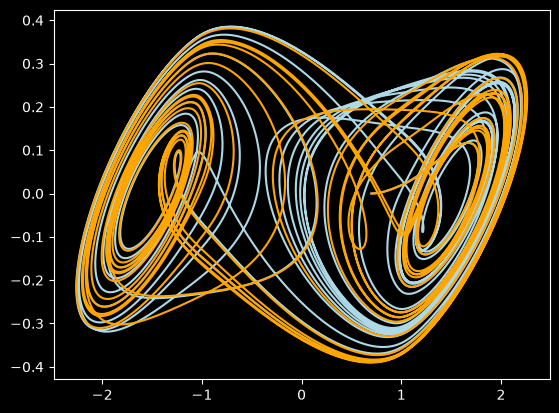

In [12]:
plt.plot(sol_1.y[0], sol_1.y[1], color="lightblue")
plt.plot(sol_2.y[0], sol_2.y[1], color="orange")

plt.show()

**5.2** Wykres dla $(x,z)$

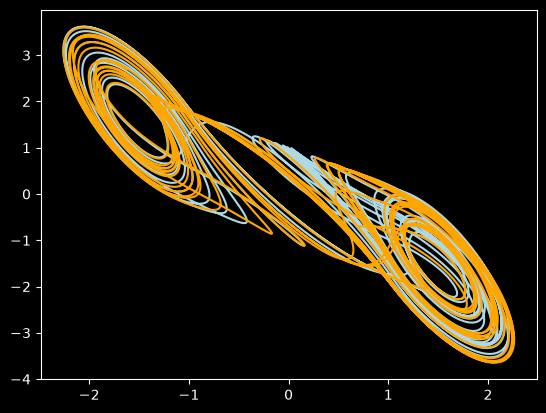

In [13]:
plt.plot(sol_1.y[0], sol_1.y[2], color="lightblue")
plt.plot(sol_2.y[0], sol_2.y[2], color="orange")

plt.show()

**5.3** Wykres dla $(y,z)$

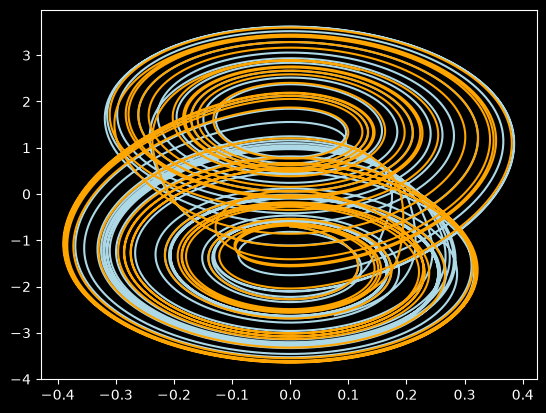

In [14]:
plt.plot(sol_1.y[1], sol_1.y[2], color="lightblue")
plt.plot(sol_2.y[1], sol_2.y[2], color="orange")

plt.show()

**Zadanie 6.** W przestrzeni trójwymiarowej wygeneruj wykres atraktora układu Chua dla rozwiązań z zadań 2 i 3.

C:\Users\Konrad\AppData\Local\Temp\ipykernel_30032\3348737626.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


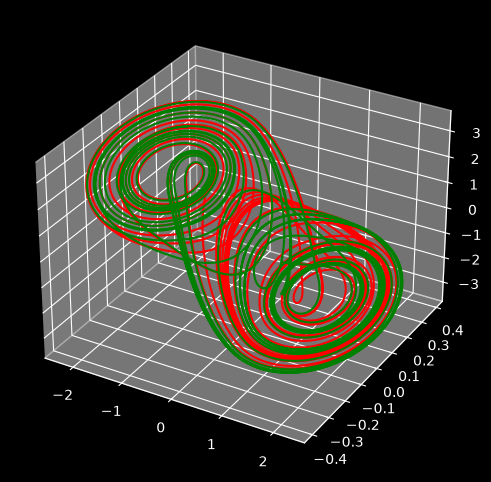

In [15]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot(sol_1.y[0], sol_1.y[1], sol_1.y[2], color="red")
ax.plot(sol_2.y[0], sol_2.y[1], sol_2.y[2], color="green")

fig.show()

**Zadanie 7.** Dla kolejnych $t$ z zadań 2 i 3 wyświetl wykres wartości $||\delta x(t)||$, $\log{\frac{||\delta x(t)||}{||\delta x(0)||}}$, $\lambda$. Korzystając z <code>np.polyfit()</code> wyznacz $\lambda_{est}$.

C:\Users\Konrad\AppData\Local\Temp\ipykernel_30032\275103626.py:5: RuntimeWarning: invalid value encountered in divide
  ly = logd/sol_1.t


Lambda estymowana: 0.081


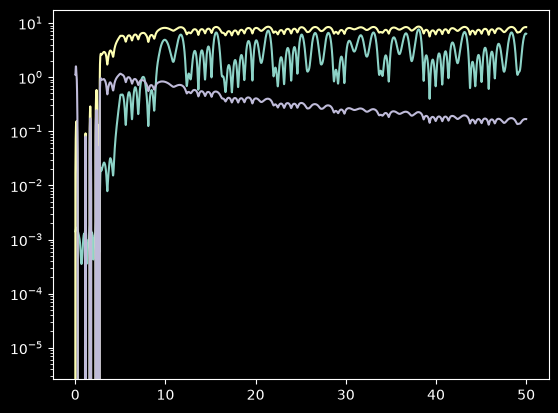

In [18]:
dt = np.linalg.norm((sol_1.y - sol_2.y), axis=0)
d0 = dt[0]

logd = np.log(dt/d0)
ly = logd/sol_1.t

start = 0
end = 10000

lam = np.polyfit(sol_1.t[start:end], logd[start:end], 1)[0]
print(f"Lambda estymowana: {lam:.3f}")

plt.semilogy(sol_1.t[start:end], dt[start:end])
plt.semilogy(sol_1.t[start:end], logd[start:end])
plt.semilogy(sol_1.t[start:end], ly[start:end])

plt.show()

### Iteracje logistyczne

Dyskretny model logistyczny z efektem Allee to matematyczne równanie opisujące, jak zmienia się liczebność populacji (np. zwierząt lub roślin) w kolejnych krokach czasowych (pokoleniach), łączące dwa kluczowe zjawiska ekologiczne: konkurencję wewnątrzgatunkową (model logistyczny) oraz efekt Allee.

W klasycznym modelu logistycznym populacja rośnie najszybciej, gdy jest mała. Efekt Allee odwraca tę zasadę dla krytycznie niskich zagęszczeń.

Aby zrozumieć ten model, należy połączyć dwa pojęcia:
1. **Dyskretny model logistyczny (równanie logistyczne):** Zakłada, że środowisko ma ograniczoną pojemność ($K$). Gdy populacja zbliża się do $K$, brakuje zasobów (jedzenia, miejsca), więc tempo wzrostu spada.
2. **Efekt Allee:** Zjawisko, w którym przy bardzo niskiej liczebności populacji osobniki mają problem z przetrwaniem lub rozmnażaniem (np. trudność w znalezieniu partnera, brak ochrony przed drapieżnikami, załamanie struktury społecznej).

Model ten zapisuje się najczęściej za pomocą równania różnicowego (ponieważ czas jest dyskretny, krok po kroku):
\(x_{n+1}=x_{n}+r\cdot x_{n}\cdot \left(1-\frac{x_{n}}{K}\right)\cdot \left(\frac{x_{n}}{A}-1\right)\)

$$ p_{t+1} = p_t+rp_t\left(1-\frac{p_t}{K}\right)\left(\frac{p_t}{A}-1\right)$$

Gdzie poszczególne symbole oznaczają:
- $x_{n}$ – liczebność (lub zagęszczenie) populacji w obecnym momencie (pokoleniu $n$).
- $x_{n+1}$ – liczebność populacji w następnym kroku czasowym.
- $r$ – wewnętrzne tempo wzrostu populacji.
- $K$ – pojemność środowiska (maksymalna liczba osobników, jaką środowisko może utrzymać).
- $A$ – próg efektu Allee ($0 < A < K$). To krytyczna wielkość populacji.

**Uwaga:** Powyższa forma reprezentuje tzw. silny efekt Allee. Istnieje też słaby efekt Allee (gdzie wzrost przy małych liczebnościach zwalnia, ale nie spada poniżej zera).

Zachowanie populacji zależy bezpośrednio od jej początkowej liczebności ($x_{0}$):
- $x_0 < A$ (Poniżej progu Allee): Czynnik $\left(\frac{x_n}{A} - 1\right)$ staje się ujemny. Populacja ma ujemne tempo wzrostu i wymiera ($x_n \to 0$).
- $A < x_0 < K$ (Pomiędzy progiem a pojemnością): Populacja rośnie i dąży do stabilnego poziomu pojemności środowiska ($x_n \to K$).
- $x_0 > K$ (Powyżej pojemności środowiska): Środowisko jest przerybione, zasobów brakuje, więc liczebność populacji spada w kierunku $K$.

**Zadanie 8.** Zaimplementuj funkcję <code>def model(r, p0, A, K, n)</code> - gdzie $n$ to ilość iteracji - obliczającą kolejne interacje modelu logistycznego z silnym efektem Alle.

**Zadanie 9.** Wygenerować wykresy ciągu ($p_t$) dla $t = 0, ..., 100$, $r = 0.5$, $A=1$, $K=2$ oraz pięciu losowych
wartości $p_0 \in (0, 1)$.


**Zadanie 10.** Napisać funkcję, która obliczy dla którego kroku $t$ wartość $p_t$ różni się od wartości $w$ o mniej niż wartość $c$. Sprawdzić działanie funkcji dla $p_0 = 0.1$, $r = 0.1$, $A=0.2$, $K=1$, $w = 0.00000002$ i $c = 10^{−9}$.

**Zadanie 11.** Wygenerować wykresy ciągu ($p_t$) dla $t = 0, ..., 100$, $r = 0.5$, $A=0.2$, $K=1$ oraz pięciu losowych
wartości $p_0 \in (0, 1)$.


**Zadanie 12.** Wygenerować wykresy ciągu ($p_t$) dla $t = 0, ..., 10\ 000$, $r = 0.75$, $A=0.2$, $K=1$ oraz dwóch losowych wartości $p_0 \in (0,1)$.

**Zadanie 13.** Wygenerować wykresy ciągu ($p_t$) dla $t = 0, ..., 10\ 000$, $r = 0.75$, $A=0.2$, $K=1$ oraz dwóch wartości $p_0$ gdzie jedna z nich powstaje w sposób $0.numeralbumu \cdot 2$ (np. numer albumu = 123456 to wartość $p_0=0.123456 \cdot 2 = 0.246912$), a druga $0.(numeralbumu+1)\cdot 2$ (np. numer albumu = 123456 to wartość $p_0=0.123457\cdot 2 = 0.0.246914$).

**Zadanie 14.** Zaimplementuj funkcję <code>def model_2(r, p0, A, K, n)</code> - gdzie $n$ to ilość iteracji - obliczającą kolejne interacje modelu logistycznego z silnym efektem Alle.

**Zadanie 15.** Zbadać rozbierzność obu modeli dla $r=0.75$, $A=0.2$, $K=1$, $n=100$ oraz $p_0=0.5$

**Zadanie 16.** Napisz funkcję <code>search_difference(model_1, model_2, diff)</code>, która wskaże w której iteracji modele różnią się od siebie o zadaną wartość <code>diff</code> ustawioną domyślnie na $10^{-2}$.

**Zadanie 17.** Wyszukaj dla jakiego $t$ modele różnią się od siebie o $10^{-3}$.

**Zadanie 18.** Wygenerować mapę punktów dla dyskretnego modelu logistycznego dla ustalonego $p_0$ oraz $r \in [0.4, 0.8]$ (zgodnie z opisanym na wykładzie algorytmem)

**Zadanie 19.** Jak brak odrzucenia początkowych wartości $p_t$ wpływa na mapę punktów?

**Odpowiedź:**

**Zadanie 20.** Czy wybór $p_0$ wpływa na zmianę mapy punktów? Wykonaj odpowiedni wykres i napisz odpowedź.

#### Wykładnik Lyapunov'a
https://pl.wikipedia.org/wiki/Wyk%C5%82adnik_Lapunowa

**Wykładnik Lyapunov'a** układu dynamicznego – miara, która charakteryzuje tempo separacji infinitezymalnie (nieskończenie) bliskich trajektorii. Pozwala on też ustalić zachowanie się układu dynamicznego dla określonych zmiennych (parametrów). Ogólnie służy do badania układów dynamicznych. Podstawy matematycznej teorii stabilności ruchu stworzył A.M.Lapunow, który rozpatrywał, jak szybko wzrasta w czasie ewolucji odległość pomiędzy dwiema bliskimi trajektoriami. Jeżeli układ dynamiczny jest chaotyczny, odległość taka rośnie w czasie $t$ wykładniczo jak $e^{t\lambda}$, gdzie współczynnik $\lambda$ zwany wykładnikiem Lapunowa jest dodatni. Wykładniki Lapunowa umożliwiają ocenę zjawiska chaotycznego w tzw. przestrzeni fazowej. Przestrzeń fazowa to inny sposób obrazowania wielowymiarowych zjawisk dynamicznych. W zwykłym przebiegu czasowym oś pozioma wykresu obrazuje czas, natomiast oś pionowa odpowiada za stan zjawiska w danej chwili (np. prędkość). W przestrzeni fazowej możemy ocenić wszystkie możliwe stany systemu w każdej chwili czasowej. Trajektoria to obraz wszystkich możliwych stanów, które przyjmuje układ w kolejnych chwilach czasu.

Jeśli przyjąć skończone i odpowiednio małe odcinki czasu, to ewolucję układu dynamicznego można opisać rekurencyjnym równaniem algebraicznym:

$$ x_{n+1}=f(x_{n})$$

gdzie:

$n$ – przyjmuje kolejne wartości całkowite, które można uznać za kolejne interwały czasowe,<br>
$x_n$ – zmienna opisująca stan układu dynamicznego w chwili $n$,<br>
$x_{n+1}$ – to stan układu dynamicznego w chwili $n+1$.

Stan układu w chwili $n+1$ otrzymuje się przez przekształcenie stanu $n$ za pomocą odpowiedniej funkcji $f$. 
Otrzymuje się wówczas ciąg o postaci:

$$ x_{n+1}=f(x_{n})$$

Wykładnik Lapunowa dla dyskretnego systemu jest zdefiniowany w postaci:
$$\lambda\left(x_0\right)=\lim_{n\rightarrow\infty}\frac{1}{n}\sum_{i=0}^{n-1}\ln\left|\frac{df(x_i)}{dx}\right|$$

Współczynnik ten jest również miarą utraty informacji o układzie w jednym przekształceniu. Mogą zaistnieć trzy możliwości:

$\lambda<0$ – orbita zmierza do stabilnego punktu lub staje się orbitą periodyczną. Ujemny wykładnik Lapunowa charakteryzuje układy dyssypatywne np. tłumione wahadło.<br>
$\lambda=0$ – orbita zmierza do neutralnego, stałego punktu. Wartość ta oznacza, że system znajduje się w najbardziej stabilnym stadium rozwoju.<br>
$\lambda>0$ – orbita jest niestabilna i chaotyczna. Dwa bliskie stany początkowe oddalają się wykładniczo od siebie z upływem czasu.

**Zadanie 21.** Napisz funkcję <code>def derivative_of_logistic(r, p, A, K)</code> liczącą wartość pochodnej równania logistycznego dla $p0$.

**Zadanie 22.** Napisz funkcję <code>def lyapunov_exponent(r, p0, A, K, n)</code>, która zwraca tablicę wartości współczynnika Lyapunov'a dla kolejnych wartości $r$.

**Zadanie 23.** Dla wartości $r\in\left[0.4,0.8\right]$, $p_0=0.5$, $A=0.2$, $K=1$ oraz $n=500$ wyświetl wykres współczynnika Lyapunov'a. Dodaj przerywaną czerwoną linię dla prostej $y=0$.

**Zadanie 24.** Porównaj wykres z zadania 15 oraz wykres z zadania 18. Napisz swoje obserwacje.

**Obserwacje:**

**Zadanie 25.** Zaproponuj swój dyskretny model nieliniowy. Zapisz wzór oraz zaimplementuj jako <code>def model_3(*args)</code>.

Wzór modelu dyskretnego

$$x_{t+1}=$$

**Zadanie 26.** Wygenerować mapę punktów modelu dla ustalonych parametrów (zgodnie z opisanym na wykładzie algorytmem).

**Zadanie 27.** Wykonaj animację 2D .gif atraktora układu Chua dla $\alpha\in\left[0,50\right]$.

**Zadanie 28.** Wykonaj animację 3D .gif atraktora układu Chua dla $\alpha\in\left[0,50\right]$.